# Matplotlib fundamentals: choosing and labelling a chart — Code-Along Template

**Type into this notebook during class.** The explanation is here; the code is not.

| | |
|---|---|
| **Follow along** | Write the code in each `# TODO` cell. The hint names the functions and arguments. |
| **If you fall behind** | Do not copy frantically. Skip to the next **CHECKPOINT**, run it, rejoin. |
| **If a cell errors** | Later cells depend on it and will fail too. Run the next CHECKPOINT rather than debugging under time pressure. |
| **After class** | The worked version is `D001_01a_Matplotlib_Fundamentals.ipynb`. Compare, do not copy. |

Cells that are already filled in are deliberate — imports and quick glances at the
data cost class time and teach nothing.

# Module 01a: Matplotlib Fundamentals

## Learning Objectives

By the end of this notebook, you will be able to:
- Understand why data visualization is essential for data analysis
- Know which chart type to use for different types of data
- Create basic plots with Matplotlib (line, scatter, bar, histogram, pie)
- Customize plots with labels, titles, colors, and legends
- Save plots as image files
- Interpret common patterns in visualizations

**Prerequisites:** Python basics, NumPy fundamentals

---

## 1. Why Visualize Data?

**"A picture is worth a thousand numbers."**

Data visualization helps us:
- **Discover patterns** - See trends, clusters, and outliers instantly
- **Communicate findings** - Share insights with non-technical audiences
- **Validate assumptions** - Check if data looks as expected
- **Guide analysis** - Decide what to investigate next

### Anscombe's Quartet: Why Summary Statistics Aren't Enough

These four datasets have nearly **identical** summary statistics:
- Same mean of X and Y
- Same standard deviation
- Same correlation coefficient

But they look completely different when visualized!

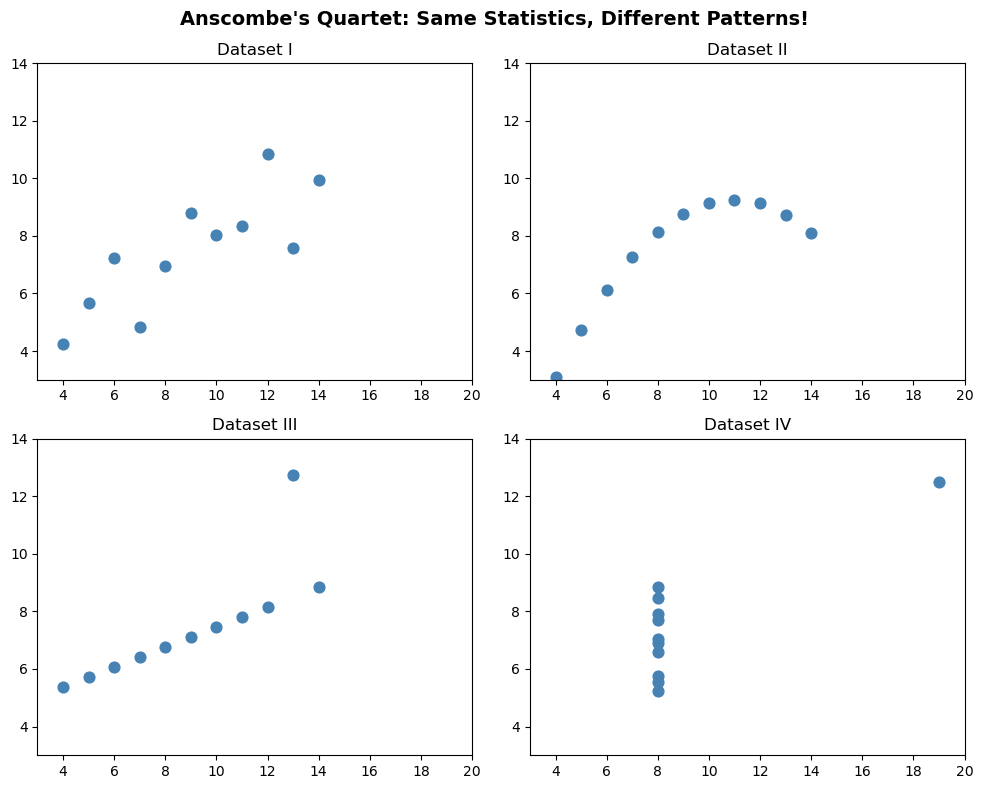

All datasets have mean(X) ≈ 9, mean(Y) ≈ 7.5, correlation ≈ 0.82
But look how different they are!


In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Anscombe's Quartet data
x1 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y1 = [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]

x2 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y2 = [9.14, 8.14, 8.74, 8.77, 9.26, 8.10, 6.13, 3.10, 9.13, 7.26, 4.74]

x3 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y3 = [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]

x4 = [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8]
y4 = [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.50, 5.56, 7.91, 6.89]

# Create 2x2 subplot
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

for ax, x, y, title in zip(axes.flat, [x1, x2, x3, x4], [y1, y2, y3, y4], ['I', 'II', 'III', 'IV']):
    ax.scatter(x, y, color='steelblue', s=60)
    ax.set_title(f'Dataset {title}')
    ax.set_xlim(3, 20)
    ax.set_ylim(3, 14)

plt.suptitle("Anscombe's Quartet: Same Statistics, Different Patterns!", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"All datasets have mean(X) ≈ 9, mean(Y) ≈ 7.5, correlation ≈ 0.82")
print("But look how different they are!")

---

## 2. Choosing the Right Chart

### Quick Decision Guide

| Your Data | Your Question | Best Chart |
|-----------|---------------|------------|
| 1 numeric variable | What's the distribution? | **Histogram** |
| 2 numeric variables | What's the relationship? | **Scatter plot** |
| Time + numeric | What's the trend over time? | **Line plot** |
| Categories + counts | How many in each group? | **Bar chart** |
| Parts of a whole | What's the composition? | **Pie chart** (use sparingly!) |

We'll learn each of these in this notebook.

---

## 3. Getting Started with Matplotlib

**Matplotlib** is Python's most popular plotting library. It's:
- Highly customizable
- Works well with NumPy and Pandas
- The foundation for other libraries (Seaborn is built on top of it)

In [3]:
# Standard imports for data visualization
import matplotlib.pyplot as plt
import numpy as np

# This line makes plots appear inline in Jupyter notebooks
%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# ═══ CHECKPOINT — "Your First Plot" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import matplotlib.pyplot as plt
import numpy as np
x1 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y1 = [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]
x2 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y2 = [9.14, 8.14, 8.74, 8.77, 9.26, 8.1, 6.13, 3.1, 9.13, 7.26, 4.74]
x3 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y3 = [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]
x4 = [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8]
y4 = [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.5, 5.56, 7.91, 6.89]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
import matplotlib.pyplot as plt
import numpy as np

print("Checkpoint restored. Ready for: Your First Plot")

### Your First Plot

The basic pattern for creating a plot:
1. Create data
2. Call a plotting function (e.g., `plt.plot()`)
3. Add customizations (title, labels)
4. Display with `plt.show()`

In [ ]:
# TODO: draw a `plt.plot`
# Hint: plt.plot, plt.xlabel, plt.ylabel, plt.title, plt.show
# Name your result: x, y

### Try It Yourself

Modify the code below to plot the squares of numbers 1-10.

In [5]:
# Your code here
x = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
y = # Calculate squares: [1, 4, 9, 16, ...]

# Create the plot


SyntaxError: invalid syntax (1183997283.py, line 3)

---

## 4. Line Plots

**When to use:** Show trends over time or continuous data.

**Common uses:**
- Stock prices over time
- Temperature throughout a day
- Website traffic by hour

In [ ]:
# TODO: draw a `plt.figure`
# Hint: plt.figure, plt.plot, plt.xlabel, plt.ylabel, plt.title
# Name your result: months, sales_2023, sales_2024

### Key Parameters for Line Plots

| Parameter | Description | Example |
|-----------|-------------|---------|
| `marker` | Shape of data points | `'o'`, `'s'`, `'^'`, `'*'` |
| `linestyle` | Type of line | `'-'`, `'--'`, `':'`, `'-.'` |
| `color` | Line color | `'blue'`, `'red'`, `'#1f77b4'` |
| `linewidth` | Thickness of line | `1`, `2`, `3` |
| `label` | Text for legend | Any string |

In [ ]:
# TODO: compute `x`
# Hint: np.linspace, plt.figure, plt.plot, plt.xlabel, plt.ylabel
# Name your result: x

In [ ]:
# ═══ CHECKPOINT — "How to Interpret Line Plots" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import matplotlib.pyplot as plt
import numpy as np
x1 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y1 = [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]
x2 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y2 = [9.14, 8.14, 8.74, 8.77, 9.26, 8.1, 6.13, 3.1, 9.13, 7.26, 4.74]
x3 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y3 = [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]
x4 = [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8]
y4 = [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.5, 5.56, 7.91, 6.89]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
import matplotlib.pyplot as plt
import numpy as np
x = [1, 2, 3, 4, 5]
y = [2, 4, 6, 8, 10]
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
sales_2023 = [45, 52, 48, 61, 55, 67, 72, 68, 75, 82, 89, 95]
sales_2024 = [50, 58, 55, 68, 63, 75, 80, 77, 85, 92, 98, 105]
x = np.linspace(0, 10, 50)

print("Checkpoint restored. Ready for: How to Interpret Line Plots")

### How to Interpret Line Plots

| Pattern | What It Means |
|---------|---------------|
| **Upward slope** | Values increasing over time |
| **Downward slope** | Values decreasing over time |
| **Flat line** | No change |
| **Steep slope** | Rapid change |
| **Cyclical pattern** | Seasonal or repeating behavior |

---

## 5. Scatter Plots

**When to use:** Explore relationships between two numeric variables.

**Common uses:**
- Height vs. Weight
- Price vs. Sales
- Study time vs. Test scores

In [ ]:
# TODO: compute `study_hours`, `exam_scores`
# Hint: np.random.seed, np.random.uniform, plt.figure, plt.scatter, plt.xlabel
# Name your result: study_hours, exam_scores

### Key Parameters for Scatter Plots

| Parameter | Description | Example |
|-----------|-------------|---------|
| `s` | Size of points | `20`, `100`, or array |
| `c` | Color of points | `'red'` or array of values |
| `alpha` | Transparency (0-1) | `0.5` for semi-transparent |
| `marker` | Shape of points | `'o'`, `'s'`, `'^'` |

In [ ]:
# TODO: compute `x`, `y`, `sizes`
# Hint: np.random.seed, np.random.uniform, plt.figure, plt.scatter, plt.colorbar
# Name your result: x, y, sizes, colors

### How to Interpret Scatter Plots

| Pattern | What It Means |
|---------|---------------|
| **Points trend upward** | Positive correlation (as X increases, Y increases) |
| **Points trend downward** | Negative correlation (as X increases, Y decreases) |
| **No clear pattern** | No linear relationship |
| **Tight cluster** | Strong relationship |
| **Spread out points** | Weak relationship |
| **Separate clusters** | Possible subgroups in data |

---

## 6. Bar Charts

**When to use:** Compare values across categories.

**Common uses:**
- Sales by product
- Population by country
- Survey responses

In [ ]:
# TODO: draw a `plt.figure`
# Hint: plt.figure, plt.bar, plt.xlabel, plt.ylabel, plt.title
# Name your result: products, sales, bars

### Horizontal Bar Charts

Use `plt.barh()` when:
- Category names are long
- You have many categories

In [ ]:
# TODO: draw a `plt.figure`
# Hint: plt.figure, plt.barh, plt.xlabel, plt.title, plt.show
# Name your result: countries, gdp

In [ ]:
# ═══ CHECKPOINT — "Grouped Bar Charts" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import matplotlib.pyplot as plt
import numpy as np
x1 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y1 = [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]
x2 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y2 = [9.14, 8.14, 8.74, 8.77, 9.26, 8.1, 6.13, 3.1, 9.13, 7.26, 4.74]
x3 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y3 = [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]
x4 = [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8]
y4 = [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.5, 5.56, 7.91, 6.89]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
import matplotlib.pyplot as plt
import numpy as np
x = [1, 2, 3, 4, 5]
y = [2, 4, 6, 8, 10]
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
sales_2023 = [45, 52, 48, 61, 55, 67, 72, 68, 75, 82, 89, 95]
sales_2024 = [50, 58, 55, 68, 63, 75, 80, 77, 85, 92, 98, 105]
x = np.linspace(0, 10, 50)
study_hours = np.random.uniform(1, 10, 30)
exam_scores = 50 + 4 * study_hours + np.random.normal(0, 5, 30)
x = np.random.uniform(0, 10, 50)
y = np.random.uniform(0, 10, 50)
sizes = np.random.uniform(50, 500, 50)
colors = np.random.uniform(0, 100, 50)
scatter = plt.scatter(x, y, s=sizes, c=colors, cmap='viridis', alpha=0.6)
products = ['Product A', 'Product B', 'Product C', 'Product D', 'Product E']
sales = [23500, 17800, 35200, 29100, 21400]
bars = plt.bar(products, sales, color='steelblue', edgecolor='navy')
countries = ['United States', 'United Kingdom', 'Germany', 'France', 'Japan']
gdp = [21.43, 2.83, 3.86, 2.72, 5.08]

print("Checkpoint restored. Ready for: Grouped Bar Charts")

### Grouped Bar Charts

Compare multiple series side by side.

In [ ]:
# TODO: compute `categories`, `product_a`, `product_b`
# Hint: np.arange, plt.figure, plt.bar, plt.xlabel, plt.ylabel
# Name your result: categories, product_a, product_b, x

---

## 7. Histograms

**When to use:** Understand the distribution of a single numeric variable.

**Common uses:**
- Age distribution of customers
- Test score distribution
- Income distribution

In [ ]:
# Example: Customer age distribution
np.random.seed(42)
ages = np.random.normal(35, 12, 1000)  # Mean=35, Std=12, 1000 customers
ages = ages[ages > 0]  # Remove negative ages

plt.figure(figsize=(10, 6))
plt.hist(ages, bins=30, color='steelblue', edgecolor='white', alpha=0.7)

# Add mean line
plt.axvline(np.mean(ages), color='red', linestyle='--', linewidth=2, label=f'Mean: {np.mean(ages):.1f}')

plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Customer Age Distribution')
plt.legend()

plt.show()

### Key Parameters for Histograms

| Parameter | Description | Example |
|-----------|-------------|---------|
| `bins` | Number of bars | `10`, `20`, `'auto'` |
| `edgecolor` | Border color | `'white'`, `'black'` |
| `alpha` | Transparency | `0.7` |
| `density` | Normalize to 1 | `True` for probability density |

### How to Interpret Histograms

| Pattern | What It Means | Example |
|---------|---------------|----------|
| **Bell curve (symmetric)** | Normal distribution | Heights, test scores |
| **Right-skewed** | Most values low, few high | Income, house prices |
| **Left-skewed** | Most values high, few low | Age at retirement |
| **Bimodal (two peaks)** | Two distinct groups | Mix of two populations |
| **Uniform** | All values equally likely | Random numbers |

In [ ]:
# Different distribution shapes
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Normal distribution
axes[0, 0].hist(np.random.normal(50, 10, 1000), bins=30, color='steelblue', edgecolor='white')
axes[0, 0].set_title('Normal (Bell Curve)')

# Right-skewed
axes[0, 1].hist(np.random.exponential(2, 1000), bins=30, color='coral', edgecolor='white')
axes[0, 1].set_title('Right-Skewed')

# Bimodal
bimodal = np.concatenate([np.random.normal(30, 5, 500), np.random.normal(60, 5, 500)])
axes[1, 0].hist(bimodal, bins=30, color='teal', edgecolor='white')
axes[1, 0].set_title('Bimodal (Two Peaks)')

# Uniform
axes[1, 1].hist(np.random.uniform(0, 100, 1000), bins=30, color='purple', edgecolor='white')
axes[1, 1].set_title('Uniform')

plt.tight_layout()
plt.show()

---

## 8. Pie Charts

**When to use:** Show parts of a whole (use sparingly!).

**Best for:**
- 2-5 categories maximum
- When percentages matter more than exact values

**Warning:** Pie charts are often harder to read than bar charts. Consider using a bar chart instead!

In [ ]:
# Example: Market share
companies = ['Company A', 'Company B', 'Company C', 'Others']
market_share = [35, 30, 20, 15]
colors = ['#2ecc71', '#3498db', '#e74c3c', '#95a5a6']
explode = [0.05, 0, 0, 0]  # Slightly explode the first slice

plt.figure(figsize=(8, 8))
plt.pie(market_share, labels=companies, autopct='%1.1f%%', 
        colors=colors, explode=explode, startangle=90,
        textprops={'fontsize': 12})

plt.title('Market Share Distribution', fontsize=14)
plt.axis('equal')  # Equal aspect ratio ensures circular pie

plt.show()

In [ ]:
# ═══ CHECKPOINT — "When NOT to Use Pie Charts" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import matplotlib.pyplot as plt
import numpy as np
x1 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y1 = [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]
x2 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y2 = [9.14, 8.14, 8.74, 8.77, 9.26, 8.1, 6.13, 3.1, 9.13, 7.26, 4.74]
x3 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y3 = [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]
x4 = [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8]
y4 = [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.5, 5.56, 7.91, 6.89]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
import matplotlib.pyplot as plt
import numpy as np
x = [1, 2, 3, 4, 5]
y = [2, 4, 6, 8, 10]
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
sales_2023 = [45, 52, 48, 61, 55, 67, 72, 68, 75, 82, 89, 95]
sales_2024 = [50, 58, 55, 68, 63, 75, 80, 77, 85, 92, 98, 105]
x = np.linspace(0, 10, 50)
study_hours = np.random.uniform(1, 10, 30)
exam_scores = 50 + 4 * study_hours + np.random.normal(0, 5, 30)
x = np.random.uniform(0, 10, 50)
y = np.random.uniform(0, 10, 50)
sizes = np.random.uniform(50, 500, 50)
colors = np.random.uniform(0, 100, 50)
scatter = plt.scatter(x, y, s=sizes, c=colors, cmap='viridis', alpha=0.6)
products = ['Product A', 'Product B', 'Product C', 'Product D', 'Product E']
sales = [23500, 17800, 35200, 29100, 21400]
bars = plt.bar(products, sales, color='steelblue', edgecolor='navy')
countries = ['United States', 'United Kingdom', 'Germany', 'France', 'Japan']
gdp = [21.43, 2.83, 3.86, 2.72, 5.08]
categories = ['Q1', 'Q2', 'Q3', 'Q4']
product_a = [25, 32, 28, 35]
product_b = [20, 25, 30, 28]
x = np.arange(len(categories))
width = 0.35
ages = np.random.normal(35, 12, 1000)
ages = ages[ages > 0]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
bimodal = np.concatenate([np.random.normal(30, 5, 500), np.random.normal(60, 5, 500)])
companies = ['Company A', 'Company B', 'Company C', 'Others']
market_share = [35, 30, 20, 15]
colors = ['#2ecc71', '#3498db', '#e74c3c', '#95a5a6']
explode = [0.05, 0, 0, 0]

print("Checkpoint restored. Ready for: When NOT to Use Pie Charts")

### When NOT to Use Pie Charts

- More than 5 categories
- Categories with similar values (hard to compare)
- When exact values matter more than proportions

**Better alternative: Horizontal bar chart**

In [ ]:
# Same data as bar chart - often clearer!
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pie chart (harder to compare)
axes[0].pie(market_share, labels=companies, autopct='%1.1f%%', colors=colors)
axes[0].set_title('Pie Chart')

# Bar chart (easier to compare)
axes[1].barh(companies, market_share, color=colors)
axes[1].set_xlabel('Market Share (%)')
axes[1].set_title('Bar Chart (Easier to Compare!)')

plt.tight_layout()
plt.show()

---

## 9. Customizing Your Plots

### Figure Size

Use `plt.figure(figsize=(width, height))` to set the size in inches.

In [ ]:
# Different figure sizes
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

x = [1, 2, 3, 4, 5]
y = [2, 4, 3, 5, 4]

axes[0].plot(x, y)
axes[0].set_title('Default proportions')

axes[1].plot(x, y)
axes[1].set_title('Same data, same subplot')

plt.show()

### Colors

Ways to specify colors:
1. **Named colors:** `'red'`, `'blue'`, `'green'`
2. **Hex codes:** `'#1f77b4'`, `'#ff7f0e'`
3. **RGB tuples:** `(0.1, 0.2, 0.5)`

In [ ]:
# Color options
x = np.linspace(0, 10, 100)

plt.figure(figsize=(10, 6))
plt.plot(x, np.sin(x), color='red', label='Named: red')
plt.plot(x, np.sin(x + 1), color='#1f77b4', label='Hex: #1f77b4')
plt.plot(x, np.sin(x + 2), color=(0.2, 0.8, 0.2), label='RGB: (0.2, 0.8, 0.2)')

plt.legend()
plt.title('Different Ways to Specify Colors')
plt.show()

### Adding Grid Lines

In [ ]:
# Grid options
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

x = [1, 2, 3, 4, 5]
y = [2, 4, 3, 5, 4]

# No grid
axes[0].plot(x, y, marker='o')
axes[0].set_title('No Grid')

# Full grid
axes[1].plot(x, y, marker='o')
axes[1].grid(True)
axes[1].set_title('Full Grid')

# Subtle grid
axes[2].plot(x, y, marker='o')
axes[2].grid(True, alpha=0.3, linestyle='--')
axes[2].set_title('Subtle Grid (Recommended)')

plt.tight_layout()
plt.show()

In [ ]:
# ═══ CHECKPOINT — "Legends" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import matplotlib.pyplot as plt
import numpy as np
x1 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y1 = [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]
x2 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y2 = [9.14, 8.14, 8.74, 8.77, 9.26, 8.1, 6.13, 3.1, 9.13, 7.26, 4.74]
x3 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y3 = [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]
x4 = [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8]
y4 = [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.5, 5.56, 7.91, 6.89]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
import matplotlib.pyplot as plt
import numpy as np
x = [1, 2, 3, 4, 5]
y = [2, 4, 6, 8, 10]
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
sales_2023 = [45, 52, 48, 61, 55, 67, 72, 68, 75, 82, 89, 95]
sales_2024 = [50, 58, 55, 68, 63, 75, 80, 77, 85, 92, 98, 105]
x = np.linspace(0, 10, 50)
study_hours = np.random.uniform(1, 10, 30)
exam_scores = 50 + 4 * study_hours + np.random.normal(0, 5, 30)
x = np.random.uniform(0, 10, 50)
y = np.random.uniform(0, 10, 50)
sizes = np.random.uniform(50, 500, 50)
colors = np.random.uniform(0, 100, 50)
scatter = plt.scatter(x, y, s=sizes, c=colors, cmap='viridis', alpha=0.6)
products = ['Product A', 'Product B', 'Product C', 'Product D', 'Product E']
sales = [23500, 17800, 35200, 29100, 21400]
bars = plt.bar(products, sales, color='steelblue', edgecolor='navy')
countries = ['United States', 'United Kingdom', 'Germany', 'France', 'Japan']
gdp = [21.43, 2.83, 3.86, 2.72, 5.08]
categories = ['Q1', 'Q2', 'Q3', 'Q4']
product_a = [25, 32, 28, 35]
product_b = [20, 25, 30, 28]
x = np.arange(len(categories))
width = 0.35
ages = np.random.normal(35, 12, 1000)
ages = ages[ages > 0]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
bimodal = np.concatenate([np.random.normal(30, 5, 500), np.random.normal(60, 5, 500)])
companies = ['Company A', 'Company B', 'Company C', 'Others']
market_share = [35, 30, 20, 15]
colors = ['#2ecc71', '#3498db', '#e74c3c', '#95a5a6']
explode = [0.05, 0, 0, 0]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = [1, 2, 3, 4, 5]
y = [2, 4, 3, 5, 4]
x = np.linspace(0, 10, 100)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
x = [1, 2, 3, 4, 5]
y = [2, 4, 3, 5, 4]

print("Checkpoint restored. Ready for: Legends")

### Legends

Add `label=` to each plot, then call `plt.legend()`

In [ ]:
# Legend positioning
x = np.linspace(0, 10, 50)

plt.figure(figsize=(10, 6))
plt.plot(x, np.sin(x), label='sin(x)')
plt.plot(x, np.cos(x), label='cos(x)')
plt.plot(x, np.sin(x) + np.cos(x), label='sin(x) + cos(x)')

# Legend location options: 'best', 'upper right', 'upper left', 'lower right', etc.
plt.legend(loc='upper right')
plt.title('Trigonometric Functions')
plt.grid(True, alpha=0.3)

plt.show()

---

## 10. Saving Your Plots

Use `plt.savefig()` to save plots as image files.

**Recommended formats:**
- **PNG** - Best for web, presentations
- **PDF** - Best for publications, high quality
- **SVG** - Best for editing later

In [ ]:
# Create a plot
x = np.linspace(0, 10, 100)
y = np.sin(x)

plt.figure(figsize=(10, 6))
plt.plot(x, y, linewidth=2)
plt.xlabel('X')
plt.ylabel('sin(X)')
plt.title('Sine Wave')
plt.grid(True, alpha=0.3)

# Save in different formats
# plt.savefig('sine_wave.png', dpi=300, bbox_inches='tight')  # High quality PNG
# plt.savefig('sine_wave.pdf', bbox_inches='tight')           # PDF for publications
# plt.savefig('sine_wave.svg', bbox_inches='tight')           # SVG for editing

plt.show()

print("Tip: Use dpi=300 for high-quality images")
print("Tip: Use bbox_inches='tight' to remove extra whitespace")

---

## 11. Interpretation Cheat Sheet

### Quick Reference: What Patterns Mean

| Chart Type | Pattern | Interpretation |
|------------|---------|----------------|
| **Line** | Upward trend | Values increasing over time |
| **Line** | Downward trend | Values decreasing over time |
| **Line** | Cyclical | Seasonal or repeating pattern |
| **Scatter** | Upward diagonal | Positive correlation |
| **Scatter** | Downward diagonal | Negative correlation |
| **Scatter** | Clusters | Distinct groups in data |
| **Histogram** | Bell curve | Normal distribution |
| **Histogram** | Right-skewed | Most values low, few high outliers |
| **Histogram** | Left-skewed | Most values high, few low outliers |
| **Histogram** | Two peaks | Two distinct groups (bimodal) |

---

## Summary

In this notebook, you learned:

1. **Why visualize?** - Pictures reveal patterns that numbers hide
2. **Chart selection:**
   - **Line plots** - Trends over time
   - **Scatter plots** - Relationships between variables
   - **Bar charts** - Compare categories
   - **Histograms** - Distribution of values
   - **Pie charts** - Parts of a whole (use sparingly!)
3. **Customization** - Labels, colors, legends, grids
4. **Saving** - PNG for web, PDF for print
5. **Interpretation** - What common patterns mean

**Next:** Continue to `01b_Seaborn_Statistical.ipynb` for statistical visualizations.

---

## Practice Exercises

Complete these exercises to solidify your understanding. Then try the full exercise notebook: `01a_Matplotlib_Exercise.ipynb`

### Exercise 1: Create a Line Plot

Create a line plot showing temperature throughout a day:
- Hours: 0, 4, 8, 12, 16, 20, 24
- Temperatures: 15, 12, 18, 25, 28, 22, 16
- Add title: "Daily Temperature"
- Add x-label: "Hour"
- Add y-label: "Temperature (°C)"

In [ ]:
# Your code here


### Exercise 2: Create a Histogram

Generate 500 random values from a normal distribution (mean=100, std=15) and create a histogram.
Add a vertical line at the mean value.

In [ ]:
# Your code here


In [ ]:
# ═══ CHECKPOINT — "Exercise 3: Create a Bar Chart" ═══════════════════════════════════════════════
#
# Run this ONLY if you are behind, or a cell above threw an error and the rest
# stopped working. It rebuilds everything this section needs, so you can rejoin
# here instead of being stuck for the rest of the class.
#
# Running it when you are NOT stuck is harmless. If it leaves you stuck anyway,
# that is a bug in the template, not in your code — say so.

import matplotlib.pyplot as plt
import numpy as np
x1 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y1 = [8.04, 6.95, 7.58, 8.81, 8.33, 9.96, 7.24, 4.26, 10.84, 4.82, 5.68]
x2 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y2 = [9.14, 8.14, 8.74, 8.77, 9.26, 8.1, 6.13, 3.1, 9.13, 7.26, 4.74]
x3 = [10, 8, 13, 9, 11, 14, 6, 4, 12, 7, 5]
y3 = [7.46, 6.77, 12.74, 7.11, 7.81, 8.84, 6.08, 5.39, 8.15, 6.42, 5.73]
x4 = [8, 8, 8, 8, 8, 8, 8, 19, 8, 8, 8]
y4 = [6.58, 5.76, 7.71, 8.84, 8.47, 7.04, 5.25, 12.5, 5.56, 7.91, 6.89]
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
import matplotlib.pyplot as plt
import numpy as np
x = [1, 2, 3, 4, 5]
y = [2, 4, 6, 8, 10]
months = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
sales_2023 = [45, 52, 48, 61, 55, 67, 72, 68, 75, 82, 89, 95]
sales_2024 = [50, 58, 55, 68, 63, 75, 80, 77, 85, 92, 98, 105]
x = np.linspace(0, 10, 50)
study_hours = np.random.uniform(1, 10, 30)
exam_scores = 50 + 4 * study_hours + np.random.normal(0, 5, 30)
x = np.random.uniform(0, 10, 50)
y = np.random.uniform(0, 10, 50)
sizes = np.random.uniform(50, 500, 50)
colors = np.random.uniform(0, 100, 50)
scatter = plt.scatter(x, y, s=sizes, c=colors, cmap='viridis', alpha=0.6)
products = ['Product A', 'Product B', 'Product C', 'Product D', 'Product E']
sales = [23500, 17800, 35200, 29100, 21400]
bars = plt.bar(products, sales, color='steelblue', edgecolor='navy')
countries = ['United States', 'United Kingdom', 'Germany', 'France', 'Japan']
gdp = [21.43, 2.83, 3.86, 2.72, 5.08]
categories = ['Q1', 'Q2', 'Q3', 'Q4']
product_a = [25, 32, 28, 35]
product_b = [20, 25, 30, 28]
x = np.arange(len(categories))
width = 0.35
ages = np.random.normal(35, 12, 1000)
ages = ages[ages > 0]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
bimodal = np.concatenate([np.random.normal(30, 5, 500), np.random.normal(60, 5, 500)])
companies = ['Company A', 'Company B', 'Company C', 'Others']
market_share = [35, 30, 20, 15]
colors = ['#2ecc71', '#3498db', '#e74c3c', '#95a5a6']
explode = [0.05, 0, 0, 0]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = [1, 2, 3, 4, 5]
y = [2, 4, 3, 5, 4]
x = np.linspace(0, 10, 100)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
x = [1, 2, 3, 4, 5]
y = [2, 4, 3, 5, 4]
x = np.linspace(0, 10, 50)
x = np.linspace(0, 10, 100)
y = np.sin(x)

print("Checkpoint restored. Ready for: Exercise 3: Create a Bar Chart")

### Exercise 3: Create a Bar Chart

Create a bar chart showing favorite programming languages:
- Languages: ['Python', 'JavaScript', 'Java', 'C++', 'Go']
- Votes: [45, 35, 20, 15, 10]
- Use different colors for each bar

In [ ]:
# Your code here
